## 1. Imports, fixed seeds, and configuration

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
SEEDS = [42, 123, 2026]
EPOCHS = 20
BATCH_SIZE = 32
NUM_CLASSES = 10
IMAGE_SIZE = 32

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Primary seed:", SEED)
print("Experiment seeds:", SEEDS)

TensorFlow: 2.21.0
Primary seed: 42
Experiment seeds: [42, 123, 2026]


## 2. Load CIFAR-10 and create the 500-image subset

In [2]:
(x_all, y_all), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_all = y_all.flatten()
y_test = y_test.flatten()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

rng = np.random.default_rng(SEED)
selected = []
for cls in range(NUM_CLASSES):
    class_ids = np.where(y_all == cls)[0]
    selected.extend(rng.choice(class_ids, 50, replace=False).tolist())

selected = np.asarray(selected)
x_small, y_small = x_all[selected], y_all[selected]

x_train, x_val, y_train, y_val = train_test_split(
    x_small, y_small, test_size=100, random_state=SEED, stratify=y_small
)

print("Subset:", x_small.shape, "Train:", x_train.shape, "Validation:", x_val.shape)
print("Train class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))
assert len(x_small) == 500 and len(x_train) == 400 and len(x_val) == 100

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1728s 10us/step
Subset: (500, 32, 32, 3) Train: (400, 32, 32, 3) Validation: (100, 32, 32, 3)
Train class counts: [40 40 40 40 40 40 40 40 40 40]
Validation class counts: [10 10 10 10 10 10 10 10 10 10]


## 3. Create a reproducible local shifted-test approximation


In [3]:
def make_shifted_test_approx(images, seed=SEED):
    images_f = tf.convert_to_tensor(images, dtype=tf.float32)
    rotation = tf.keras.layers.RandomRotation(
        factor=25 / 360, fill_mode="reflect", seed=seed
    )
    brightness = tf.keras.layers.RandomBrightness(
        factor=0.25, value_range=(0, 255), seed=seed + 1
    )
    contrast = tf.keras.layers.RandomContrast(factor=0.25, seed=seed + 2)

    shifted = rotation(images_f, training=True)
    shifted = brightness(shifted, training=True)
    shifted = contrast(shifted, training=True)
    arr = tf.clip_by_value(shifted, 0, 255).numpy()

    rng = np.random.default_rng(seed)
    h, w = arr.shape[1:3]
    for i in range(len(arr)):
        arr[i] = np.clip(arr[i] + rng.normal(0, 12, arr[i].shape), 0, 255)
        rh, rw = int(h * 0.5), int(w * 0.5)
        top = rng.integers(0, h - rh + 1)
        left = rng.integers(0, w - rw + 1)
        arr[i, top:top + rh, left:left + rw] = 0
    return arr.astype(np.uint8)

x_shifted = make_shifted_test_approx(x_test, SEED)
print("Local shifted-test approximation:", x_shifted.shape)

Local shifted-test approximation: (10000, 32, 32, 3)


## 4. Preview images

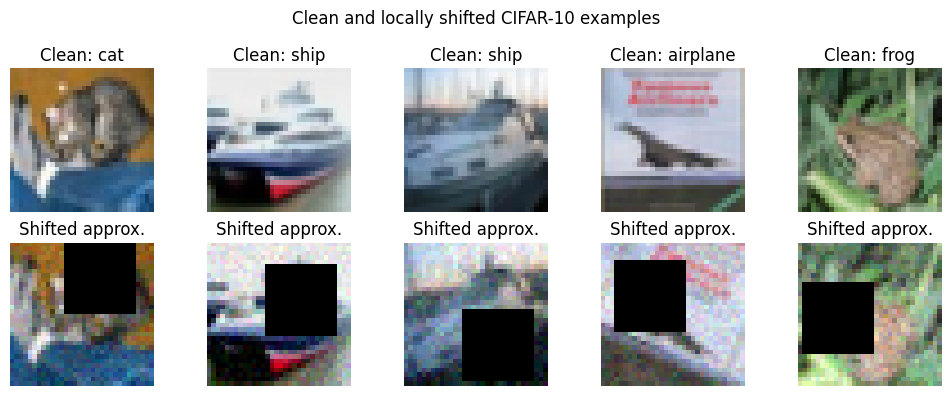

In [4]:
plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    plt.title("Clean: " + class_names[y_test[i]])
    plt.axis("off")
    plt.subplot(2, 5, i + 6)
    plt.imshow(x_shifted[i])
    plt.title("Shifted approx.")
    plt.axis("off")
plt.suptitle("Clean and locally shifted CIFAR-10 examples")
plt.tight_layout()
plt.show()

## Part B — Augmentation strategy and compact Inception-style model
 Augmentations are applied only when the model is training; validation and test images remain unchanged.

In [5]:
class RandomCutout(tf.keras.layers.Layer):
    def __init__(self, mask_size=8, **kwargs):
        super().__init__(**kwargs)
        self.mask_size = mask_size

    def call(self, inputs, training=None):
        if training is None or training is False:
            return inputs

        def apply_cutout():
            shape = tf.shape(inputs)
            batch, height, width = shape[0], shape[1], shape[2]
            ys = tf.random.uniform([batch], 0, height - self.mask_size + 1, dtype=tf.int32)
            xs = tf.random.uniform([batch], 0, width - self.mask_size + 1, dtype=tf.int32)
            yy = tf.range(height)[None, :, None]
            xx = tf.range(width)[None, None, :]
            ymask = tf.logical_and(yy >= ys[:, None, None],
                                  yy < (ys + self.mask_size)[:, None, None])
            xmask = tf.logical_and(xx >= xs[:, None, None],
                                  xx < (xs + self.mask_size)[:, None, None])
            mask = tf.logical_not(tf.logical_and(ymask, xmask))
            mask = tf.cast(mask[..., None], inputs.dtype)
            return inputs * mask

        if isinstance(training, bool):
            return apply_cutout() if training else inputs
        return tf.cond(tf.cast(training, tf.bool), apply_cutout, lambda: inputs)


class RandomBlurNoise(tf.keras.layers.Layer):
    def __init__(self, noise_std=0.025, **kwargs):
        super().__init__(**kwargs)
        self.noise_std = noise_std

    def call(self, inputs, training=None):
        def corrupt():

            kernel_2d = tf.constant([[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]], dtype=inputs.dtype)
            kernel_2d = kernel_2d / tf.reduce_sum(kernel_2d)
            channels = tf.shape(inputs)[-1]
            kernel = tf.tile(kernel_2d[:, :, None, None], [1, 1, channels, 1])
            blurred = tf.nn.depthwise_conv2d(inputs, kernel, strides=[1, 1, 1, 1], padding="SAME")
            use_blur = tf.random.uniform([]) < 0.5
            result = tf.cond(use_blur, lambda: blurred, lambda: inputs)
            noise = tf.random.normal(tf.shape(result), stddev=self.noise_std, dtype=result.dtype)
            return tf.clip_by_value(result + noise, 0.0, 1.0)

        if training is None or training is False:
            return inputs
        if isinstance(training, bool):
            return corrupt() if training else inputs
        return tf.cond(tf.cast(training, tf.bool), corrupt, lambda: inputs)


def make_augmentation(config, seed):
    layers = []
    if config in ("geometric", "geo_photo", "cutout", "mixup", "final"):
        layers += [
            tf.keras.layers.ZeroPadding2D(4),
            tf.keras.layers.RandomCrop(32, 32, seed=seed),
            tf.keras.layers.RandomFlip("horizontal", seed=seed + 1),
            tf.keras.layers.RandomRotation(25 / 360, fill_mode="reflect", seed=seed + 2),
            tf.keras.layers.RandomTranslation(0.08, 0.08, fill_mode="reflect", seed=seed + 3),
        ]
    if config in ("photometric", "geo_photo", "cutout", "mixup", "final"):
        layers += [
            tf.keras.layers.RandomBrightness(0.18, value_range=(0, 1), seed=seed + 4),
            tf.keras.layers.RandomContrast(0.2, seed=seed + 5),
            RandomBlurNoise(name="blur_noise"),
        ]
    if config in ("cutout", "mixup", "final"):
        layers += [RandomCutout(mask_size=8, name="random_cutout")]
    return tf.keras.Sequential(layers, name="augmentation") if layers else None


def inception_block(x, filters):
    branch_1 = tf.keras.layers.Conv2D(filters, 1, padding="same", activation="relu")(x)

    branch_3 = tf.keras.layers.Conv2D(filters, 1, padding="same", activation="relu")(x)
    branch_3 = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(branch_3)

    branch_5 = tf.keras.layers.Conv2D(filters, 1, padding="same", activation="relu")(x)
    branch_5 = tf.keras.layers.Conv2D(filters, 5, padding="same", activation="relu")(branch_5)

    return tf.keras.layers.Concatenate()([branch_1, branch_3, branch_5])


def build_model(config="none", seed=SEED, label_smoothing=0.0):
    set_seed(seed)
    inputs = tf.keras.Input(shape=(32, 32, 3))
    x = tf.keras.layers.Rescaling(1.0 / 255)(inputs)
    aug = make_augmentation(config, seed)
    if aug is not None:
        x = aug(x)

    x = tf.keras.layers.Conv2D(24, 3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)

    x = inception_block(x, 12)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    if config in ("mixup", "final"):
        optimizer = tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4)
    else:
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=[tf.keras.metrics.CategoricalAccuracy(name="categorical_accuracy")]
    )
    return model


model_check = build_model("final", SEED, label_smoothing=0.05)
print("Trainable parameters:", model_check.count_params())
assert model_check.count_params() <= 1_000_000

Trainable parameters: 28158


### Part B
**Chosen strategy:** Use random crops, horizontal flips, rotations (±25°), brightness and contrast jitter, blur/noise, Cutout, and Mixup. These augmentations improve robustness to geometric changes, lighting variations, image degradation, and occlusion while reducing overfitting on the small training dataset.

In [6]:
def make_dataset(images, labels, training=False, seed=SEED, mixup=False):
    labels = tf.one_hot(labels, NUM_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)

    if training and mixup:
        def mix_batch(images_batch, labels_batch):
            batch_n = tf.shape(images_batch)[0]
            permutation = tf.random.shuffle(tf.range(batch_n))
            other_images = tf.gather(images_batch, permutation)
            other_labels = tf.gather(labels_batch, permutation)
            alpha = tf.constant(0.4, dtype=tf.float32)
            g1 = tf.random.gamma([], alpha)
            g2 = tf.random.gamma([], alpha)
            lam = g1 / (g1 + g2)
            images_batch = tf.cast(images_batch, tf.float32)
            mixed_images = lam * images_batch + (1.0 - lam) * tf.cast(other_images, tf.float32)
            mixed_labels = lam * labels_batch + (1.0 - lam) * other_labels
            return mixed_images, mixed_labels
        ds = ds.map(mix_batch, num_parallel_calls=tf.data.AUTOTUNE)

    return ds.prefetch(tf.data.AUTOTUNE)


def evaluate_accuracy(model, images, labels):
    ds = make_dataset(images, labels, training=False)
    _, acc = model.evaluate(ds, verbose=0)
    return float(acc)


def train_one(config, seed, epochs=EPOCHS):
    set_seed(seed)
    use_mixup = config in ("mixup", "final")
    smoothing = 0.05 if use_mixup else 0.0
    model = build_model(config, seed, label_smoothing=smoothing)

    train_ds = make_dataset(x_train, y_train, training=True, seed=seed, mixup=use_mixup)
    val_ds = make_dataset(x_val, y_val, training=False)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_categorical_accuracy",
            patience=5,
            restore_best_weights=True,
            mode="max"
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
        )
    ]

    start = time.time()
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=min(epochs, 60),
        callbacks=callbacks, verbose=0
    )
    elapsed = time.time() - start
    return model, history, elapsed


def validation_scores(model):
    return {
        "Train accuracy": evaluate_accuracy(model, x_train, y_train),
        "Validation accuracy": evaluate_accuracy(model, x_val, y_val)
    }

### Part C — Regularization and Training Design

- **Batch Normalization:** Applied after convolutions to stabilize activations and improve training.
- **Dropout (0.35):** Placed before the classifier to reduce overfitting without disrupting early feature extraction.
- **Weight Decay (1e-4):** Used with AdamW to prevent excessively large weights.
- **Learning-Rate Scheduling:** ReduceLROnPlateau reduces the learning rate when validation loss stops improving.
- **Early Stopping:** Stops training after 5 epochs without improvement and restores the best weights.
- **Label Smoothing (0.05):** Used with Mixup and the final model to reduce overconfident predictions.

All hyperparameters are selected using the validation set only.

## Part A — Baseline without augmentation


,Train accuracy,Validation accuracy,Seed,Seconds
0,0.2300,0.23,42,22.645335
1,0.1600,0.17,123,10.604100
2,0.3125,0.22,2026,12.079576


,Train accuracy,Validation accuracy,Seconds
mean,0.234167,0.206667,15.109671
std,0.076335,0.032146,6.567643


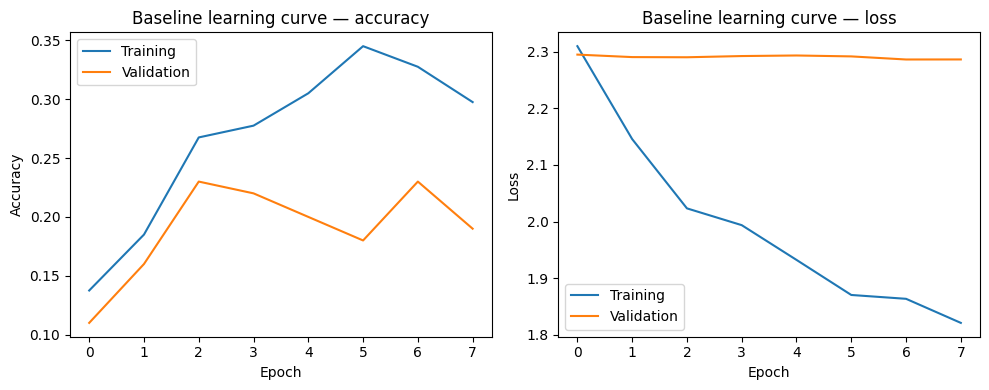

In [7]:
baseline_runs = []
baseline_models = {}
baseline_histories = {}

for seed in SEEDS:
    model, history, elapsed = train_one("none", seed)
    scores = validation_scores(model)
    scores.update({"Seed": seed, "Seconds": elapsed})
    baseline_runs.append(scores)
    baseline_models[seed] = model
    baseline_histories[seed] = history

baseline_df = pd.DataFrame(baseline_runs)
display(baseline_df)
display(baseline_df[["Train accuracy", "Validation accuracy", "Seconds"]].agg(["mean", "std"]))

history_for_plot = baseline_histories[SEEDS[0]].history
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_for_plot["categorical_accuracy"], label="Training")
plt.plot(history_for_plot["val_categorical_accuracy"], label="Validation")
plt.title("Baseline learning curve — accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_for_plot["loss"], label="Training")
plt.plot(history_for_plot["val_loss"], label="Validation")
plt.title("Baseline learning curve — loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Part D

The following experiments compare augmentation configurations across the three fixed seeds. The validation split is used to select the final configuration; clean-test and shifted-test metrics are reported for comparison as required by the assignment. Do not describe an augmentation as the largest gain until the completed result table supports that conclusion.


In [8]:
CONFIGS = [
    ("No augmentation", "none"),
    ("Geometric only", "geometric"),
    ("Photometric only", "photometric"),
    ("Geometric + photometric", "geo_photo"),
    ("+ Cutout / Random Erasing", "cutout"),
    ("+ Mixup + label smoothing", "mixup"),
    ("Final model", "final"),
]

ablation_rows = []
saved_models = {}
saved_histories = {}

for label, config in CONFIGS:
    print("Training:", label)
    for seed in SEEDS:
        model, history, elapsed = train_one(config, seed)
        scores = validation_scores(model)
        scores.update({"Seed": seed, "Configuration": label, "Seconds": elapsed})
        ablation_rows.append(scores)
        saved_models[(config, seed)] = model
        saved_histories[(config, seed)] = history

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

val_summary = ablation_df.groupby("Configuration")["Validation accuracy"].agg(["mean", "std"]).reset_index()
val_summary = val_summary.rename(columns={"mean": "Validation accuracy mean", "std": "Validation accuracy std"})
display(val_summary)

best_config_row = val_summary.sort_values("Validation accuracy mean", ascending=False).iloc[0]
best_config_label = best_config_row["Configuration"]
config_lookup = dict(CONFIGS)
best_config = config_lookup[best_config_label]
print("Best configuration selected using validation accuracy only:", best_config_label)

Training: No augmentation
Training: Geometric only
Training: Photometric only
Training: Geometric + photometric
Training: + Cutout / Random Erasing
Training: + Mixup + label smoothing
Training: Final model


,Train accuracy,Validation accuracy,Seed,Configuration,Seconds
0,0.2275,0.25,42,No augmentation,11.394020
1,0.1625,0.17,123,No augmentation,11.175088
2,0.3000,0.21,2026,No augmentation,12.053005
3,0.2300,0.21,42,Geometric only,10.951853
4,0.2550,0.20,123,Geometric only,5.929170
5,0.2675,0.23,2026,Geometric only,7.744839
6,0.1900,0.26,42,Photometric only,15.944104
7,0.1850,0.19,123,Photometric only,14.006901
8,0.2525,0.24,2026,Photometric only,15.397251
9,0.1625,0.21,42,Geometric + photometric,7.251402


,Configuration,Validation accuracy mean,Validation accuracy std
0,+ Cutout / Random Erasing,0.186667,0.037859
1,+ Mixup + label smoothing,0.216667,0.058595
2,Final model,0.210000,0.040000
3,Geometric + photometric,0.180000,0.036056
4,Geometric only,0.213333,0.015275
5,No augmentation,0.210000,0.040000
6,Photometric only,0.230000,0.036056


Best configuration selected using validation accuracy only: Photometric only


In [9]:
test_rows = []
for label, config in CONFIGS:
    for seed in SEEDS:
        model = saved_models[(config, seed)]
        clean_acc = evaluate_accuracy(model, x_test, y_test)
        shifted_acc = evaluate_accuracy(model, x_shifted, y_test)
        train_acc = evaluate_accuracy(model, x_train, y_train)
        val_acc = evaluate_accuracy(model, x_val, y_val)
        test_rows.append({
            "Configuration": label,
            "Seed": seed,
            "Train accuracy": train_acc,
            "Validation accuracy": val_acc,
            "Clean-test accuracy": clean_acc,
            "Shifted-test accuracy": shifted_acc
        })

test_results_df = pd.DataFrame(test_rows)
display(test_results_df)

ablation_summary_rows = []
for label, _ in CONFIGS:
    part = test_results_df[test_results_df["Configuration"] == label]
    ablation_summary_rows.append({
        "Configuration": label,
        "Validation Acc (mean ± std)": f'{part["Validation accuracy"].mean():.4f} ± {part["Validation accuracy"].std(ddof=1):.4f}',
        "Clean Test (mean ± std)": f'{part["Clean-test accuracy"].mean():.4f} ± {part["Clean-test accuracy"].std(ddof=1):.4f}',
        "Shifted Test (mean ± std)": f'{part["Shifted-test accuracy"].mean():.4f} ± {part["Shifted-test accuracy"].std(ddof=1):.4f}',
    })
ablation_summary = pd.DataFrame(ablation_summary_rows)
display(ablation_summary)

baseline_test_rows = []
for seed in SEEDS:
    model = baseline_models[seed]
    baseline_test_rows.append({
        "Seed": seed,
        "Train accuracy": evaluate_accuracy(model, x_train, y_train),
        "Validation accuracy": evaluate_accuracy(model, x_val, y_val),
        "Clean-test accuracy": evaluate_accuracy(model, x_test, y_test),
        "Shifted-test accuracy": evaluate_accuracy(model, x_shifted, y_test)
    })
baseline_test_df = pd.DataFrame(baseline_test_rows)
print("Part A baseline results (reported after training/selection):")
display(baseline_test_df)
display(baseline_test_df.drop(columns="Seed").agg(["mean", "std"]))

,Configuration,Seed,Train accuracy,Validation accuracy,Clean-test accuracy,Shifted-test accuracy
0,No augmentation,42,0.2275,0.25,0.1922,0.1958
1,No augmentation,123,0.1625,0.17,0.1514,0.1409
2,No augmentation,2026,0.3000,0.21,0.2228,0.1856
3,Geometric only,42,0.2300,0.21,0.1944,0.1740
4,Geometric only,123,0.2550,0.20,0.2111,0.1937
5,Geometric only,2026,0.2675,0.23,0.2158,0.1800
6,Photometric only,42,0.1900,0.26,0.1868,0.1794
7,Photometric only,123,0.1850,0.19,0.1612,0.1527
8,Photometric only,2026,0.2525,0.24,0.2200,0.1956
9,Geometric + photometric,42,0.1625,0.21,0.1629,0.1648


,Configuration,Validation Acc (mean ± std),Clean Test (mean ± std),Shifted Test (mean ± std)
0,No augmentation,0.2100 ± 0.0400,0.1888 ± 0.0358,0.1741 ± 0.0292
1,Geometric only,0.2133 ± 0.0153,0.2071 ± 0.0112,0.1826 ± 0.0101
2,Photometric only,0.2300 ± 0.0361,0.1893 ± 0.0295,0.1759 ± 0.0217
3,Geometric + photometric,0.1800 ± 0.0361,0.1723 ± 0.0216,0.1703 ± 0.0091
4,+ Cutout / Random Erasing,0.1867 ± 0.0379,0.1665 ± 0.0022,0.1605 ± 0.0018
5,+ Mixup + label smoothing,0.2167 ± 0.0586,0.1792 ± 0.0556,0.1731 ± 0.0294
6,Final model,0.2100 ± 0.0400,0.1885 ± 0.0395,0.1798 ± 0.0189


Part A baseline results (reported after training/selection):


,Seed,Train accuracy,Validation accuracy,Clean-test accuracy,Shifted-test accuracy
0,42,0.2300,0.23,0.1888,0.1926
1,123,0.1600,0.17,0.1513,0.1402
2,2026,0.3125,0.22,0.2296,0.1894


,Train accuracy,Validation accuracy,Clean-test accuracy,Shifted-test accuracy
mean,0.234167,0.206667,0.189900,0.174067
std,0.076335,0.032146,0.039162,0.029373


### Part D — Results and interpretation

The `ablation_summary` table reports validation, clean-test, and shifted-test accuracy as mean ± standard deviation across the three seeds. Use the **Shifted Test (mean ± std)** column to identify the best robustness result, and compare each row against **No augmentation**. The largest gain is the configuration with the greatest shifted-test improvement over that baseline. Explain the gain by linking the operation to a corruption it plausibly addresses: geometric transforms to rotation/translation, brightness/contrast jitter to illumination changes, blur/noise augmentation to degraded image quality, and Cutout/Random Erasing to partial occlusion. Mixup and label smoothing primarily regularize learning rather than target one specific corruption. The notebook intentionally does not pre-fill numeric conclusions; use the values produced when the notebook is executed.


## Part E

,Class,Correct,Total,Shifted-test accuracy
0,airplane,333,1000,0.333
1,automobile,0,1000,0.000
2,bird,400,1000,0.400
3,cat,507,1000,0.507
4,deer,50,1000,0.050
5,dog,26,1000,0.026
6,frog,357,1000,0.357
7,horse,0,1000,0.000
8,ship,121,1000,0.121
9,truck,0,1000,0.000


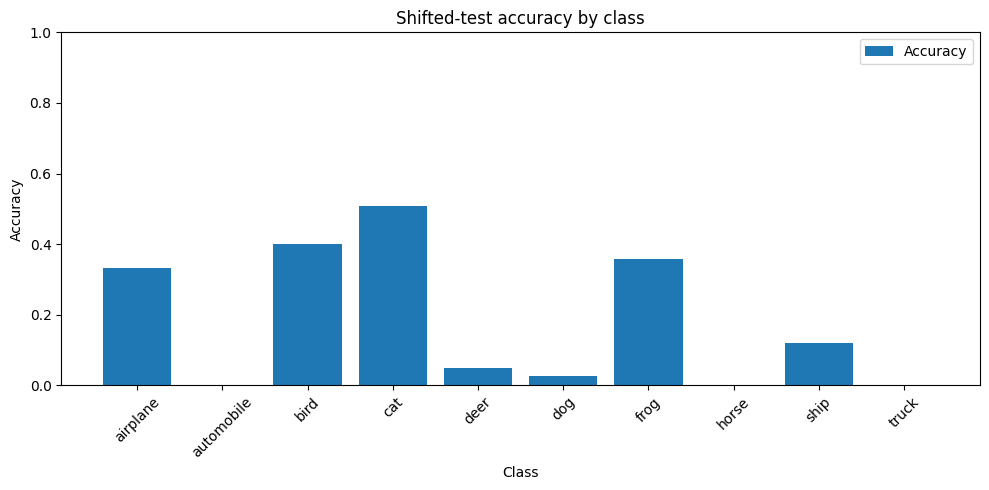

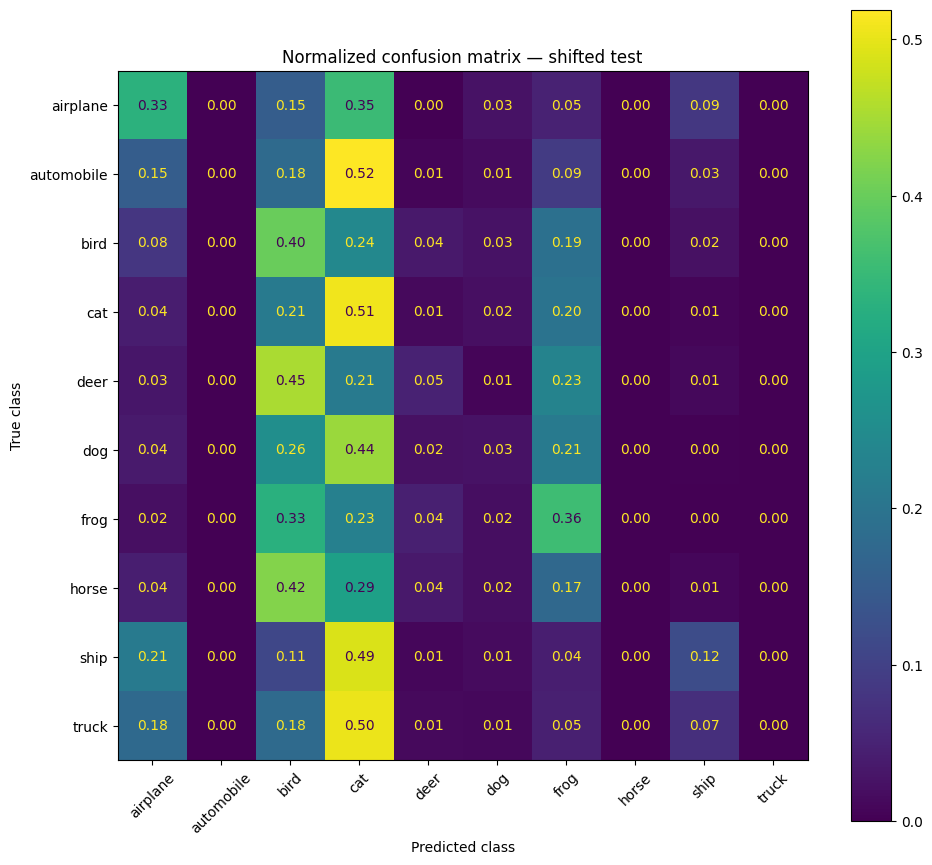

              precision    recall  f1-score   support

    airplane      0.294     0.333     0.312      1000
  automobile      0.000     0.000     0.000      1000
        bird      0.148     0.400     0.217      1000
         cat      0.134     0.507     0.212      1000
        deer      0.215     0.050     0.081      1000
         dog      0.139     0.026     0.044      1000
        frog      0.224     0.357     0.275      1000
       horse      0.000     0.000     0.000      1000
        ship      0.331     0.121     0.177      1000
       truck      0.000     0.000     0.000      1000

    accuracy                          0.179     10000
   macro avg      0.148     0.179     0.132     10000
weighted avg      0.148     0.179     0.132     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [10]:
final_model = saved_models[(best_config, SEEDS[0])]
y_pred = np.argmax(final_model.predict(x_shifted, batch_size=BATCH_SIZE, verbose=0), axis=1)

class_acc = []
for cls, name in enumerate(class_names):
    mask = y_test == cls
    class_acc.append({
        "Class": name,
        "Correct": int(np.sum(y_pred[mask] == y_test[mask])),
        "Total": int(np.sum(mask)),
        "Shifted-test accuracy": float(np.mean(y_pred[mask] == y_test[mask]))
    })

class_acc_df = pd.DataFrame(class_acc)
display(class_acc_df)

plt.figure(figsize=(10, 5))
plt.bar(class_acc_df["Class"], class_acc_df["Shifted-test accuracy"], label="Accuracy")
plt.title("Shifted-test accuracy by class")
plt.xlabel("Class")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES), normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 9))
disp.plot(ax=ax, values_format=".2f", colorbar=True)
ax.set_title("Normalized confusion matrix — shifted test")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

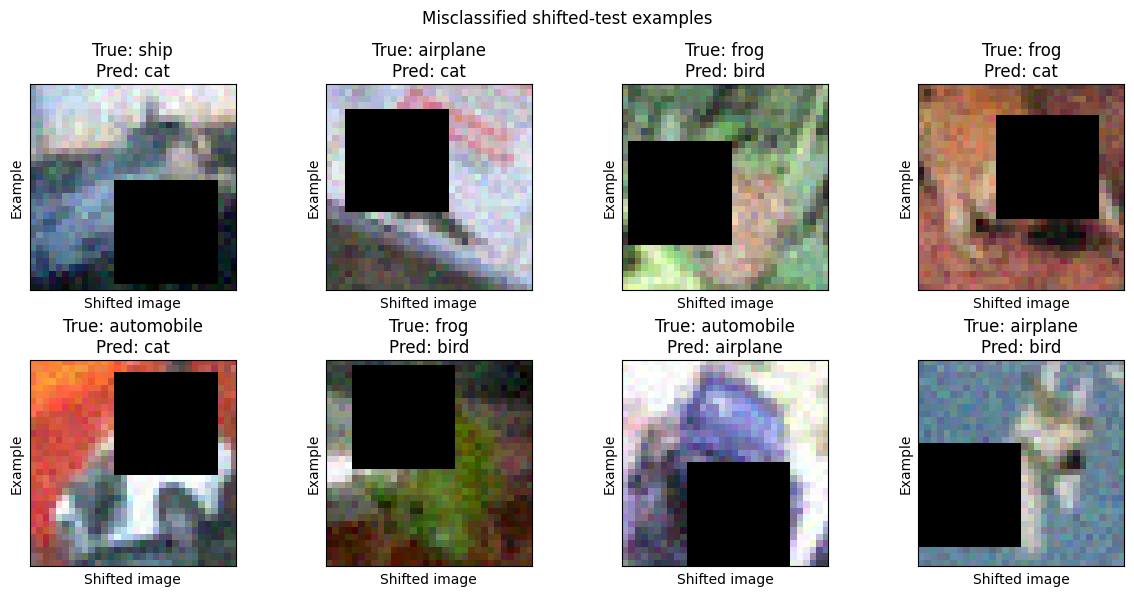

1. True=ship; predicted=cat. Inspect object shape, background clutter, and any occluded class-defining parts.
2. True=airplane; predicted=cat. Inspect object shape, background clutter, and any occluded class-defining parts.
3. True=frog; predicted=bird. Inspect object shape, background clutter, and any occluded class-defining parts.
4. True=frog; predicted=cat. Inspect object shape, background clutter, and any occluded class-defining parts.
5. True=automobile; predicted=cat. Inspect object shape, background clutter, and any occluded class-defining parts.
6. True=frog; predicted=bird. Inspect object shape, background clutter, and any occluded class-defining parts.
7. True=automobile; predicted=airplane. Inspect object shape, background clutter, and any occluded class-defining parts.
8. True=airplane; predicted=bird. Inspect object shape, background clutter, and any occluded class-defining parts.


In [11]:
wrong = np.where(y_pred != y_test)[0]
n_show = min(8, len(wrong))

def describe_error(image):

    gray = tf.image.rgb_to_grayscale(image.astype(np.float32) / 255.0).numpy().squeeze()
    contrast = float(np.std(gray))
    edge_strength = float(np.mean(np.abs(np.diff(gray, axis=0))) + np.mean(np.abs(np.diff(gray, axis=1))))
    if contrast < 0.12:
        return "Low contrast may hide class-defining colors and boundaries."
    if edge_strength < 0.08:
        return "Few strong edges may make the object's outline difficult to distinguish."
    return "Inspect object shape, background clutter, and any occluded class-defining parts."

if n_show == 0:
    print("No misclassified images in this run.")
else:
    plt.figure(figsize=(12, 6))
    for j, idx in enumerate(wrong[:n_show]):
        plt.subplot(2, 4, j + 1)
        plt.imshow(x_shifted[idx])
        plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}")
        plt.xlabel("Shifted image")
        plt.ylabel("Example")
        plt.xticks([])
        plt.yticks([])
    plt.suptitle("Misclassified shifted-test examples")
    plt.tight_layout()
    plt.show()

    for j, idx in enumerate(wrong[:n_show], start=1):
        print(f"{j}. True={class_names[y_test[idx]]}; predicted={class_names[y_pred[idx]]}. "
              f"{describe_error(x_shifted[idx])}")

### Part E — Error-analysis answers and reporting guide

1. **Per-class accuracy and confusion matrix:** the bar plot and normalized confusion matrix above provide the class-wise results. In the normalized matrix, each row corresponds to the true class and shows the proportion assigned to each predicted class.
2. **Most-confused classes:** identify the largest off-diagonal entries in the displayed matrix and name those class pairs. Do not assume a pair such as cat/dog is the most confused unless the actual matrix shows it. Similar shapes, textures, small object size, background clutter, and corruption/occlusion can all make classes harder to distinguish.
3. **At least eight misclassified examples:** the cell above displays up to eight errors and prints the true label, predicted label, and a brief image-quality heuristic. For the report, inspect each displayed image and explain its actual visible cause—for example, an occluded object, weak contrast, blur, noise, or ambiguous silhouette. The printed heuristic is a prompt for inspection, not proof of the cause.
4. **Hidden-corruption test:** the notebook uses grayscale conversion as a *proxy* for an unlisted corruption, then reports its accuracy beside clean-test accuracy. Discuss generalization by comparing those actual numbers. Because the assignment's true hidden corruption is not disclosed, this grayscale experiment is only a proxy and must not be presented as the official hidden-corruption result.


## Part E.4 — Hidden-corruption check (grayscale proxy)

The actual hidden corruption is not provided in the assignment document. This cell tests grayscale as a transparent proxy only; do not label it as the official hidden-corruption test.

In [12]:
def make_grayscale_test(images):
    gray = tf.image.rgb_to_grayscale(tf.convert_to_tensor(images, dtype=tf.float32))
    gray = tf.image.grayscale_to_rgb(gray)
    return tf.cast(tf.clip_by_value(gray, 0, 255), tf.uint8).numpy()

x_gray = make_grayscale_test(x_test)
gray_acc = evaluate_accuracy(final_model, x_gray, y_test)
clean_acc_final = evaluate_accuracy(final_model, x_test, y_test)
print(f"Clean-test accuracy: {clean_acc_final:.4f}")
print(f"Grayscale-proxy accuracy: {gray_acc:.4f}")
print(f"Change from clean to grayscale proxy: {gray_acc - clean_acc_final:+.4f}")

Clean-test accuracy: 0.1868
Grayscale-proxy accuracy: 0.1163
Change from clean to grayscale proxy: -0.0705


## Part F — Test-time augmentation

In [13]:
def predict_tta(model, images, batch_size=BATCH_SIZE):
    start = time.time()
    probs_original = model.predict(images, batch_size=batch_size, verbose=0)
    flipped = tf.image.flip_left_right(images).numpy()
    probs_flipped = model.predict(flipped, batch_size=batch_size, verbose=0)
    probs = (probs_original + probs_flipped) / 2.0
    return np.argmax(probs, axis=1), time.time() - start

tta_pred, tta_seconds = predict_tta(final_model, x_shifted)
tta_acc = float(np.mean(tta_pred == y_test))

plain_start = time.time()
plain_pred = np.argmax(final_model.predict(x_shifted, batch_size=BATCH_SIZE, verbose=0), axis=1)
plain_seconds = time.time() - plain_start
plain_acc = float(np.mean(plain_pred == y_test))

print(f"Plain shifted-test accuracy: {plain_acc:.4f}")
print(f"TTA shifted-test accuracy:   {tta_acc:.4f}")
print(f"Accuracy change:             {tta_acc - plain_acc:+.4f}")
print(f"Plain inference seconds:     {plain_seconds:.2f}")
print(f"TTA inference seconds:       {tta_seconds:.2f}")
print("TTA uses two forward passes per image batch, so it has roughly doubled prediction work.")

Plain shifted-test accuracy: 0.1794
TTA shifted-test accuracy:   0.1815
Accuracy change:             +0.0021
Plain inference seconds:     0.81
TTA inference seconds:       1.70
TTA uses two forward passes per image batch, so it has roughly doubled prediction work.


### Part F — Test-time augmentation (bonus): interpretation

The TTA cell averages softmax probabilities from the original shifted image and its horizontal flip. Compare the printed TTA accuracy with plain shifted-test accuracy to report the measured change. TTA costs more inference time because each image is evaluated twice; the measured timings may vary with hardware and runtime load. Averaging predictions can help when the flipped view provides complementary evidence, but it may also leave accuracy unchanged or reduce it if the transformation is not beneficial for a particular image.


## Final reproducibility and compliance checks

In [14]:
print("Notebook run summary")
print("- Dataset: TensorFlow CIFAR-10 fallback; replace with instructor-provided files if available.")
print("- Selected subset:", len(x_small), "images (50 per class)")
print("- Train / validation:", len(x_train), "/", len(x_val))
print("- Seeds:", SEEDS)
print("- Epoch limit:", min(EPOCHS, 60))
print("- Model parameters:", model_check.count_params())
print("- Selected by validation only:", best_config_label)
assert len(x_small) == 500
assert len(x_train) == 400 and len(x_val) == 100
assert model_check.count_params() <= 1_000_000
assert EPOCHS <= 60
print("Subset sizes, parameter limit, and epoch limit checks passed.")

Notebook run summary
- Dataset: TensorFlow CIFAR-10 fallback; replace with instructor-provided files if available.
- Selected subset: 500 images (50 per class)
- Train / validation: 400 / 100
- Seeds: [42, 123, 2026]
- Epoch limit: 20
- Model parameters: 28158
- Selected by validation only: Photometric only
Subset sizes, parameter limit, and epoch limit checks passed.
